In [1]:
import torch
from segmentation_models import *

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("CUDA device found.")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("MPS device found.")
else:
    device = torch.device("cpu")
    print("Using CPU.")

CUDA device found.


/media/data/Mironshoh/segmentation-paper/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# **CVC-ClinicDB Dataset**

In [3]:
# Dataset Paths
dataset_path = "data/CVC-ClinicDB"
image_dir = "Original"
mask_dir = "Ground Truth"

# Image Preprocessing Parameters
IMG_SIZE = (256, 256)  # Changed to (256, 256) as per the context

dataset = MedicalImageSegmentationData(
    dataset_path=dataset_path,
    image_dir=image_dir,
    mask_dir=mask_dir,
    img_size=IMG_SIZE,
    batch_size=8,
    test_size=0.1,
    random_state=42,
    binarize_mask=True,
)

train_loader, test_loader = dataset.dataloaders()

print(f"Total number of samples: {len(dataset)}")
print(f"Number of training samples: {len(train_loader.dataset)}")
print(f"Number of testing samples: {len(test_loader.dataset)}")

# dataset.visualize_samples()

Total number of samples: 612
Number of training samples: 550
Number of testing samples: 62


# Unet CVC model training config

In [ ]:
cfg = TrainConfig(
    # --- General ---
    model_name = "ResUNetPP",
    dataset_name = "CVC-ClinicDB",
    criterion = "BCEDiceLoss",
    optimizer = "AdamW",
    epochs = 100,
    lr = 1e-3,
    weight_decay = 1e-4,

    # --- Scheduler ---
    scheduler = "ReduceLROnPlateau",
    scheduler_factor = 0.5,          # for ReduceLROnPlateau
    scheduler_patience = 5,            # for ReduceLROnPlateau
    mode = "min",

    # --- Training control ---
    early_stopping_patience = 10,

    # --- Paths / logging ---
    base_dir="model_comparisons",
    models_dir = "trained_models",
    history_dir = "models_history",
    loss_dir = "loss_plots",
    visualize_dir = "visualizations",
    logs_dir = "logs",
    use_wandb = True,
    wandb_project = "segmentation_models",
    wandb_run_name = None,
    wandb_watch_log_freq = 100,

    # --- Metrics ---
    threshold = 0.5,
    log_train_metrics = True
)

In [5]:
if cfg.use_wandb:
    from dotenv import load_dotenv
    load_dotenv()
    import wandb
    wandb.login(key=os.getenv("WANDB_API_KEY"))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /home/humblebee/.netrc
wandb: Currently logged in as: mironshoh (iv-drip-counter) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [6]:
model = create_resunetpp(config='standard', in_channels=3, num_classes=1)
trainer = SegmentationTrainer(model, device, train_loader, test_loader, test_loader, cfg=cfg)
result = trainer.train()
result


2025-09-04 17:26:00 | INFO | ResUNetPP_model_CVC_ClinicDB_20250904_172600 | Logging to model_comparisons/logs/ResUNetPP_model_CVC_ClinicDB_20250904_172600.log
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


2025-09-04 17:26:01 | INFO | ResUNetPP_model_CVC_ClinicDB_20250904_172600 | W&B URL: https://wandb.ai/iv-drip-counter/segmentation_models/runs/0xvtc218
100%|██████████| 8/8 [00:01<00:00,  7.95it/s]
2025-09-04 17:26:26 | INFO | ResUNetPP_model_CVC_ClinicDB_20250904_172600 | Epoch 001/5 | Train: 1.033119 | Val: 0.857200 | LR: 0.000100 | 24.94s | Val Dice: 0.3808 IoU: 0.2685 F1: 0.4754
2025-09-04 17:26:26 | INFO | ResUNetPP_model_CVC_ClinicDB_20250904_172600 | Saved best: model_comparisons/models/best_ResUNetPP_model_CVC_ClinicDB_20250904_172600.pth (val=0.857200)
100%|██████████| 8/8 [00:01<00:00,  6.90it/s]
2025-09-04 17:26:51 | INFO | ResUNetPP_model_CVC_ClinicDB_20250904_172600 | Epoch 002/5 | Train: 0.789176 | Val: 0.854969 | LR: 0.000100 | 24.52s | Val Dice: 0.4005 IoU: 0.2851 F1: 0.4707
2025-09-04 17:26:51 | INFO | ResUNetPP_model_CVC_ClinicDB_20250904_172600 | Saved best: model_comparisons/models/best_ResUNetPP_model_CVC_ClinicDB_20250904_172600.pth (val=0.854969)
100%|██████████|

avg_flops,▁▁▁▁▁
avg_fps,█▂▂▁▄
avg_gflops,▁▁▁▁▁
avg_inference_time,▁▇▇█▅
epoch_seconds,█▃▂▁▃
lr,▁▁▁▁▁
num_trainable,▁▁▁▁▁
train/dice,▁▄▆▇█
train/f1,▁▄▆▇█
train/iou,▁▄▆▇█
+11,...


{'best_val_loss': 0.7161537259817123,
 'epochs_ran': 5,
 'best_model_path': 'model_comparisons/models/best_ResUNetPP_model_CVC_ClinicDB_20250904_172600.pth',
 'loss_csv_path': 'model_comparisons/history/loss_history_ResUNetPP_CVC_ClinicDB_20250904_172600.csv',
 'wandb_url': 'https://wandb.ai/iv-drip-counter/segmentation_models/runs/0xvtc218',
 'log_path': 'model_comparisons/logs/ResUNetPP_model_CVC_ClinicDB_20250904_172600.log'}

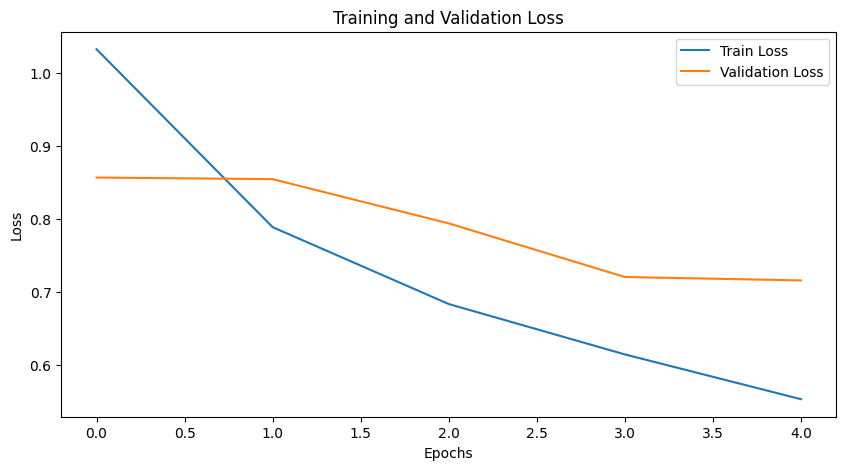

In [7]:
trainer.plot_losses()

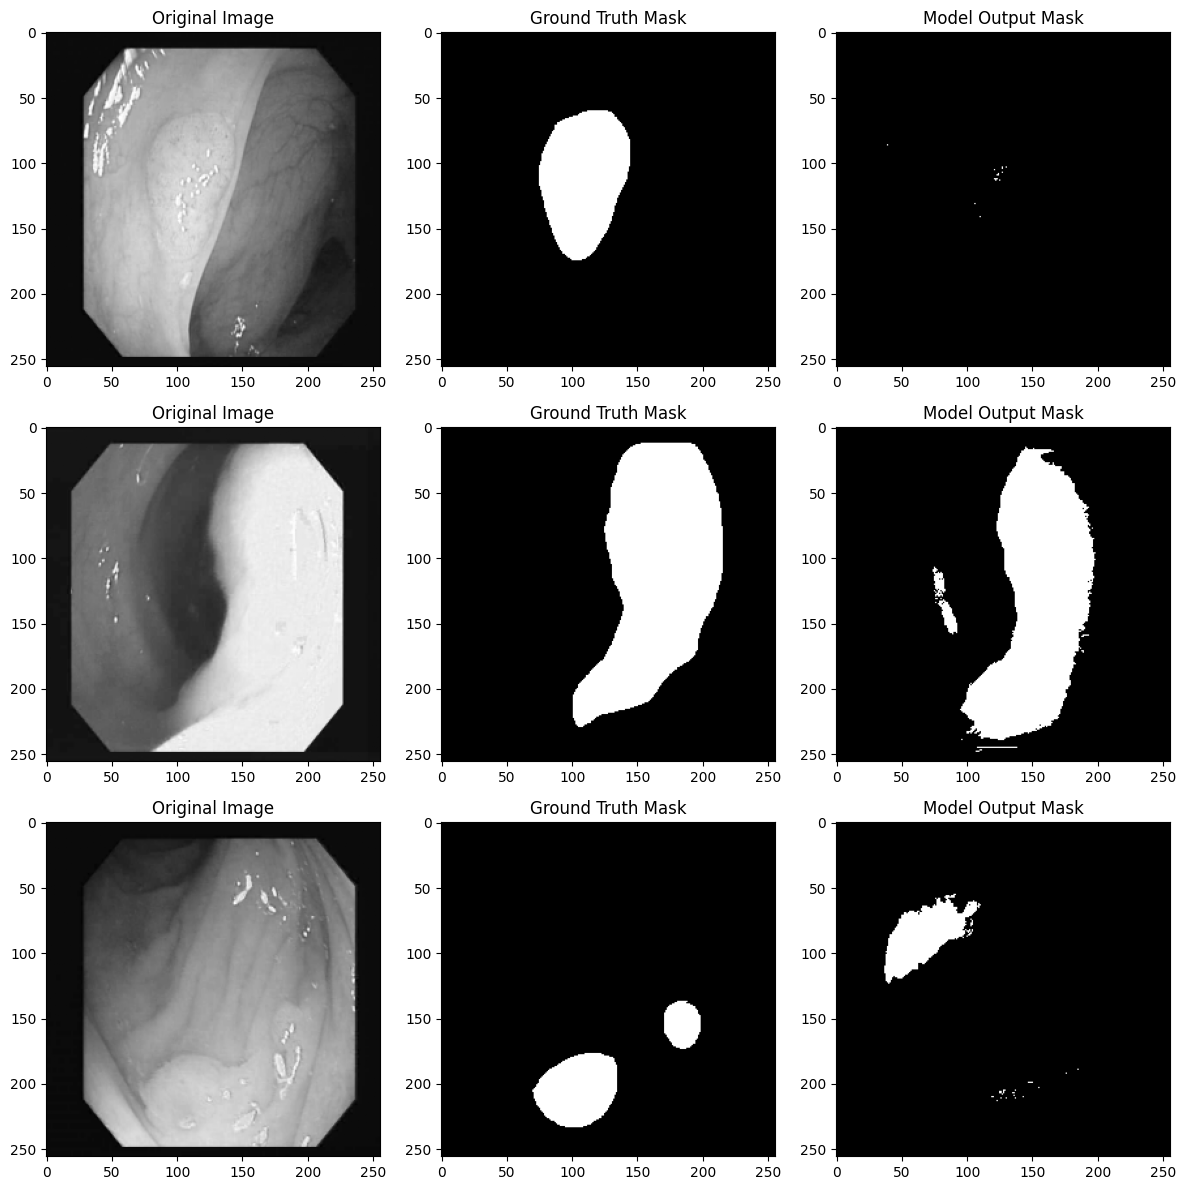

In [8]:
trainer.visualize_output_samples()

In [9]:
trainer.validate_and_save()

100%|██████████| 8/8 [00:01<00:00,  7.96it/s]



MODEL EVALUATION RESULTS
Test Loss                          : 0.7162
Average Dice Score                 : 0.4503
Average Hausdorff Distance         : 102.5150
Average IoU                        : 0.3423
Precision                          : 0.5270
Recall                             : 0.6405
F1 Score                           : 0.5782
IoU (batch avg)                    : 0.4087
Dice (batch avg)                   : 0.5733
Total Parameters                   : 27,125,221
Trainable Parameters               : 27,125,221
Average Inference Time (seconds)   : 0.074985
FPS (Frames Per Second)            : 13.34
FLOPs                              : 58,868,882,752.0
GFLOPs                             : 58.8689

Results saved to: model_comparisons/evaluation_results/ResUNetPP_model_CVC-ClinicDB_evaluation_results_20250904_172600.csv
Validation results saved to model_comparisons/evaluation_results/ResUNetPP_model_CVC-ClinicDB_evaluation_results


{'test_loss': 0.7161537259817123,
 'avg_dice_score': 0.450306153614671,
 'avg_hd_score': 102.51504445075989,
 'avg_iou': 0.34231722886147986,
 'precision': 0.5269819900394468,
 'recall': 0.6405417235253225,
 'f1': 0.5782391368069554,
 'iou_batch_avg': 0.4087143000215292,
 'dice_batch_avg': 0.5733157843351364,
 'total_params': 27125221,
 'trainable_params': 27125221,
 'avg_inference_time': 0.0749845027923584,
 'fps': 13.336088961863586,
 'flops': 58868882752.0,
 'gflops': 58.868882752}

# **Kvasir-SEG dataset**

In [11]:
import torch
from segmentation_models import *

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("CUDA device found.")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("MPS device found.")
else:
    device = torch.device("cpu")
    print("Using CPU.")

CUDA device found.


Total number of samples: 1000
Number of training samples: 900
Number of testing samples: 100


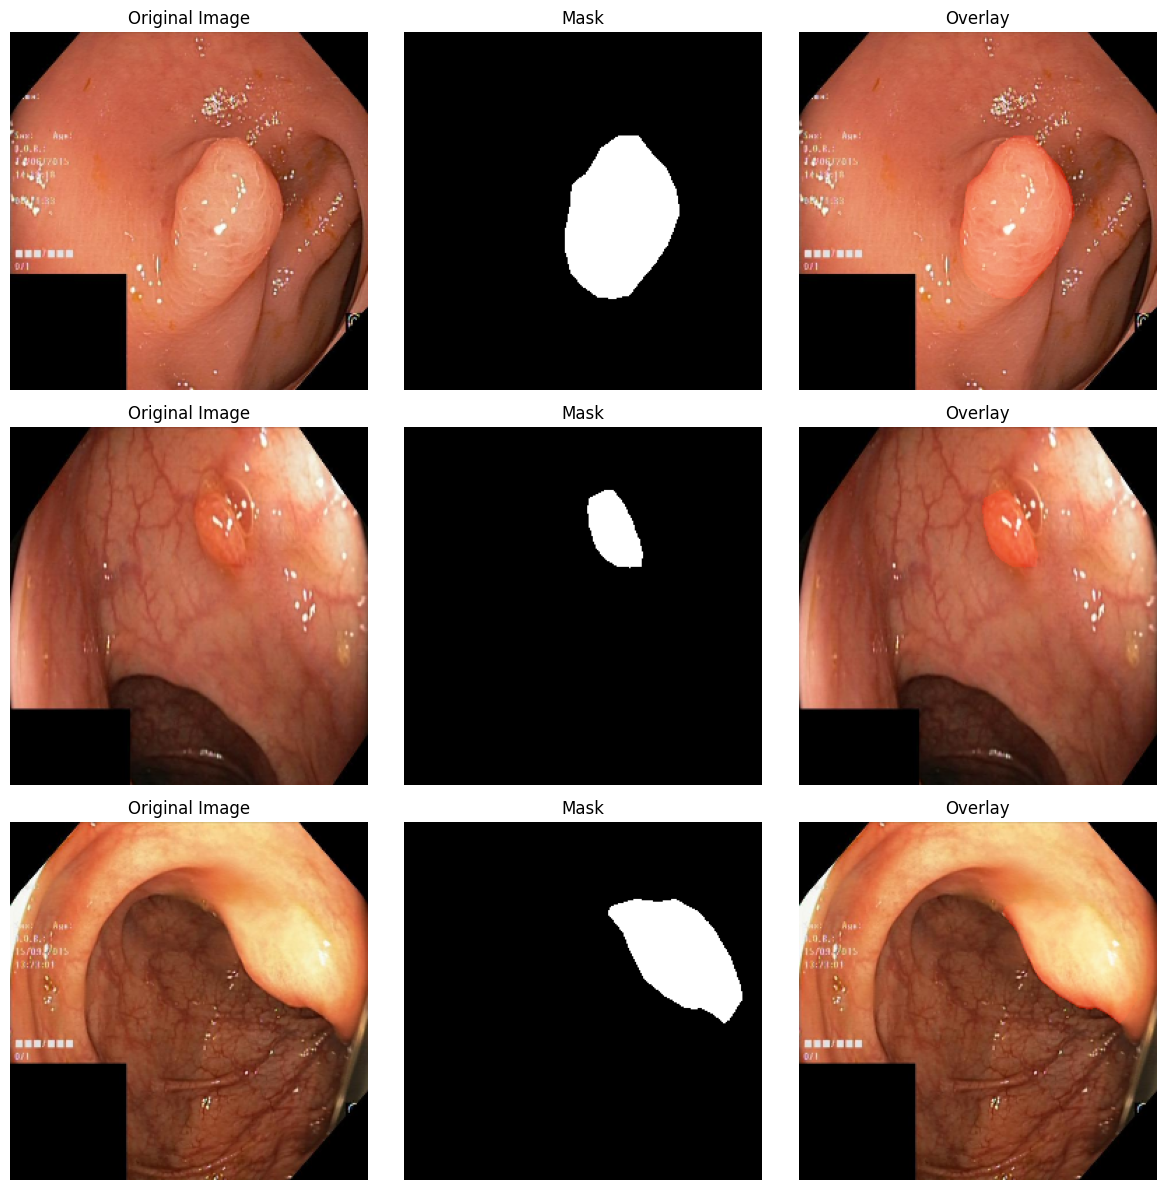

In [10]:
# Dataset Paths
dataset_path = "data/Kvasir-SEG"
image_dir = "images"
mask_dir = "masks"

# Image Preprocessing Parameters
IMG_SIZE = (256, 256)  # Changed to (256, 256) as per the context

dataset = MedicalImageSegmentationData(
    dataset_path=dataset_path,
    image_dir=image_dir,
    mask_dir=mask_dir,
    img_size=IMG_SIZE,
    batch_size=8,
    test_size=0.1,
    random_state=42,
    binarize_mask=True,
)

train_loader, test_loader = dataset.dataloaders()

print(f"Total number of samples: {len(dataset)}")
print(f"Number of training samples: {len(train_loader.dataset)}")
print(f"Number of testing samples: {len(test_loader.dataset)}")

dataset.visualize_samples()

# UNet Kvasir training config

In [ ]:
cfg = TrainConfig(
    # --- General ---
    model_name = "ResUNetPP",
    dataset_name = "Kvasir-SEG",
    criterion = "BCEDiceLoss",
    optimizer = "AdamW",
    epochs = 100,
    lr = 1e-3,
    weight_decay = 1e-4,

    # --- Scheduler ---
    scheduler = "ReduceLROnPlateau",
    scheduler_factor = 0.5,          # for ReduceLROnPlateau
    scheduler_patience = 5,            # for ReduceLROnPlateau
    mode = "min",

    # --- Training control ---
    early_stopping_patience = 10,

    # --- Paths / logging ---
    base_dir="model_comparisons",
    models_dir = "trained_models",
    history_dir = "models_history",
    loss_dir = "loss_plots",
    visualize_dir = "visualizations",
    logs_dir = "logs",
    use_wandb = True,
    wandb_project = "segmentation_models",
    wandb_run_name = None,
    wandb_watch_log_freq = 100,

    # --- Metrics ---
    threshold = 0.5,
    log_train_metrics = True
)

In [13]:
if cfg.use_wandb:
    from dotenv import load_dotenv
    load_dotenv()
    import wandb
    wandb.login(key=os.getenv("WANDB_API_KEY"))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /home/humblebee/.netrc


In [14]:
model = create_resunetpp(config='standard', in_channels=3, num_classes=1)
trainer = SegmentationTrainer(model, device, train_loader, test_loader, test_loader, cfg=cfg)
result = trainer.train()
result


2025-09-04 17:28:27 | INFO | ResUNetPP_model_Kvasir_SEG_20250904_172827 | Logging to model_comparisons/logs/ResUNetPP_model_Kvasir_SEG_20250904_172827.log


2025-09-04 17:28:27 | INFO | ResUNetPP_model_Kvasir_SEG_20250904_172827 | W&B URL: https://wandb.ai/iv-drip-counter/segmentation_models/runs/u2zi4e2c
100%|██████████| 13/13 [00:02<00:00,  5.99it/s]
2025-09-04 17:29:06 | INFO | ResUNetPP_model_Kvasir_SEG_20250904_172827 | Epoch 001/5 | Train: 0.999619 | Val: 0.866078 | LR: 0.000100 | 38.07s | Val Dice: 0.4800 IoU: 0.3494 F1: 0.5356
2025-09-04 17:29:06 | INFO | ResUNetPP_model_Kvasir_SEG_20250904_172827 | Saved best: model_comparisons/models/best_ResUNetPP_model_Kvasir_SEG_20250904_172827.pth (val=0.866078)
100%|██████████| 13/13 [00:01<00:00,  7.01it/s]
2025-09-04 17:29:44 | INFO | ResUNetPP_model_Kvasir_SEG_20250904_172827 | Epoch 002/5 | Train: 0.819707 | Val: 0.801658 | LR: 0.000100 | 37.54s | Val Dice: 0.5241 IoU: 0.3953 F1: 0.5716
2025-09-04 17:29:44 | INFO | ResUNetPP_model_Kvasir_SEG_20250904_172827 | Saved best: model_comparisons/models/best_ResUNetPP_model_Kvasir_SEG_20250904_172827.pth (val=0.801658)
100%|██████████| 13/13 [00

avg_flops,▁▁▁▁▁
avg_fps,█▁▃▄▁
avg_gflops,▁▁▁▁▁
avg_inference_time,▁█▆▅█
epoch_seconds,▂▁▁▁█
lr,▁▁▁▁▁
num_trainable,▁▁▁▁▁
train/dice,▁▄▆▇█
train/f1,▁▄▆▇█
train/iou,▁▄▅▇█
+11,...


{'best_val_loss': 0.7544667308147137,
 'epochs_ran': 5,
 'best_model_path': 'model_comparisons/models/best_ResUNetPP_model_Kvasir_SEG_20250904_172827.pth',
 'loss_csv_path': 'model_comparisons/history/loss_history_ResUNetPP_Kvasir_SEG_20250904_172827.csv',
 'wandb_url': 'https://wandb.ai/iv-drip-counter/segmentation_models/runs/u2zi4e2c',
 'log_path': 'model_comparisons/logs/ResUNetPP_model_Kvasir_SEG_20250904_172827.log'}

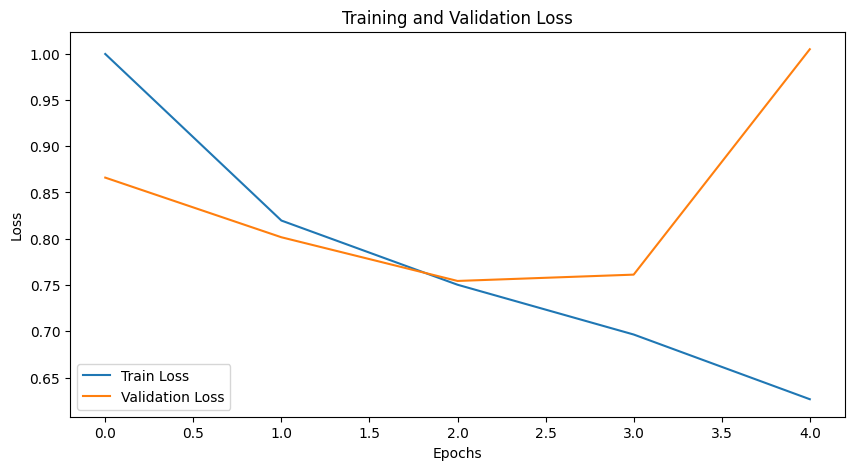

In [15]:
trainer.plot_losses()

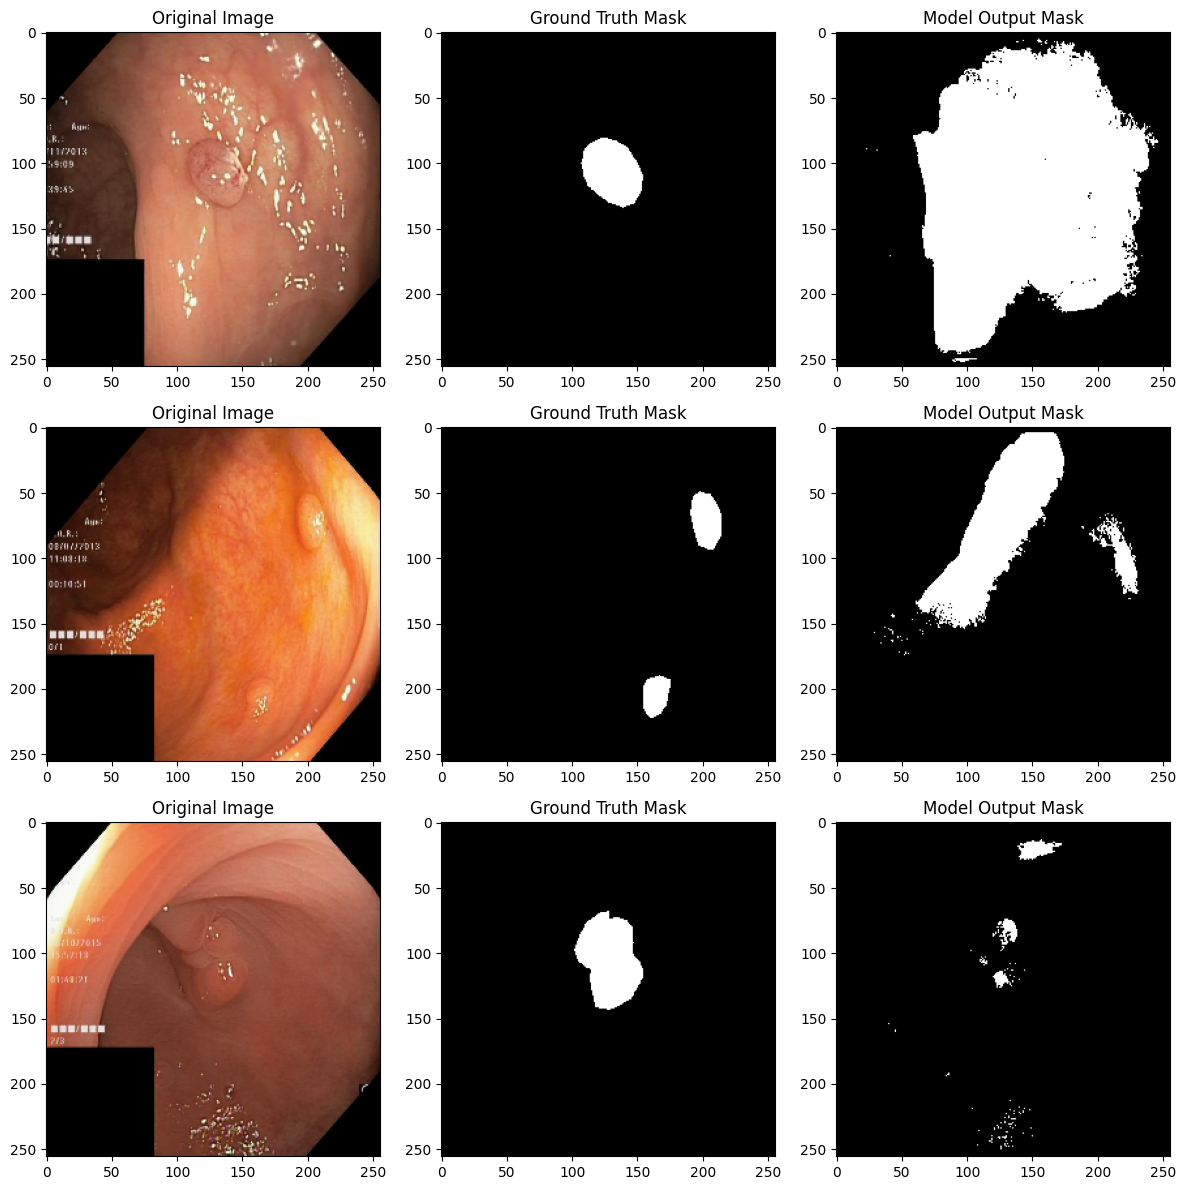

In [16]:
trainer.visualize_output_samples()

In [17]:
trainer.validate_and_save()

100%|██████████| 13/13 [00:06<00:00,  1.86it/s]



MODEL EVALUATION RESULTS
Test Loss                          : 1.0048
Average Dice Score                 : 0.5211
Average Hausdorff Distance         : inf
Average IoU                        : 0.3866
Precision                          : 0.4079
Recall                             : 0.8481
F1 Score                           : 0.5509
IoU (batch avg)                    : 0.3817
Dice (batch avg)                   : 0.5412
Total Parameters                   : 27,125,221
Trainable Parameters               : 27,125,221
Average Inference Time (seconds)   : 0.075145
FPS (Frames Per Second)            : 13.31
FLOPs                              : 58,868,882,752.0
GFLOPs                             : 58.8689

Results saved to: model_comparisons/evaluation_results/ResUNetPP_model_Kvasir-SEG_evaluation_results_20250904_172827.csv
Validation results saved to model_comparisons/evaluation_results/ResUNetPP_model_Kvasir-SEG_evaluation_results


{'test_loss': 1.0047543415656457,
 'avg_dice_score': 0.5210946018809811,
 'avg_hd_score': inf,
 'avg_iou': 0.386644920599869,
 'precision': 0.4078959658252517,
 'recall': 0.848147466105558,
 'f1': 0.5508661899016624,
 'iou_batch_avg': 0.3816750817573987,
 'dice_batch_avg': 0.5411999202691592,
 'total_params': 27125221,
 'trainable_params': 27125221,
 'avg_inference_time': 0.07514535903930664,
 'fps': 13.307541713613016,
 'flops': 58868882752.0,
 'gflops': 58.868882752}